# Comprehensive Exploratory Data Analysis & Visual Insight Studio
### A Generic, Automated EDA Pipeline with Multi-Modal Visualizations
**Key Capabilities:**
1. **Automated Directory Scanner**: Auto-detects delimiters (`,`, `;`, `\t`), encodings (`UTF-8`, `UTF-8-BOM`), and inspects all dataset shapes.
2. **Schema & Data Type Profiling**: Intelligently classifies columns into Numerical Continuous, Numerical Discrete, Categorical (Nominal/Ordinal), Datetime, Unique Identifiers, and Text.
3. **Interactive Target Selection**: Lets the user specify any target column dynamically (with automated task detection: Continuous -> Regression vs. Categorical -> Classification).
4. **Traditional EDA Engine**:
   - **Target Analysis**: Distribution shapes, skewness, kurtosis, outliers, class balance, log-transform tests.
   - **Features Analysis**: Univariate distributions, Pareto charts, missingness, cardinality, low-variance checks.
   - **Feature x Feature**: Pearson/Spearman correlation heatmaps, multicollinearity flags (|r| > 0.70), pairplots, Cramér's V associations.
   - **Target x Feature**: Predictive relationships, regression slopes, ANOVA F-tests, Cohen's d, normalized stacked distributions.
5. **Visual Vocabulary Suite**: Leverages the 9 visual families (Deviation, Correlation, Change over Time, Ranking, Distribution, Part-to-Whole, Magnitude, Spatial, Flow).


In [33]:
# Cell 1: Environment Setup & Core Dependencies
import os
import glob
import csv
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
# Pandas display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 150)
pd.set_option('display.expand_frame_repr', False)

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set high-resolution visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

# Professional colorblind-safe color palette (Okabe-Ito inspired)
PALETTE = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7', '#56B4E9', '#F0E442', '#333333']
sns.set_palette(PALETTE)

print("Environment configured successfully. Ready for data ingestion.")


Environment configured successfully. Ready for data ingestion.


## 1. Automated File Scanner & Ingestion Engine
Scans the target directory, sniffs delimiters (handles European `;`, standard `,`, tabs `\t`, pipes `|`), inspects file sizes, and generates an inventory table.


In [34]:
 #Cell: Dataset Selection & Automated Schema Profiling
import os
import pandas as pd
import numpy as np

# Your raw directory path
DATA_DIR = r"C:\Users\frank\Desktop\A Charts Tale\data\raw"

def load_and_profile_dataset(file_path, delimiter=";"):
    """Loads a dataset from file_path and computes comprehensive schema profile."""
    # If passed just a file name, resolve it using DATA_DIR or inventory_df
    if not os.path.exists(file_path):
        candidate = os.path.join(DATA_DIR, file_path)
        if os.path.exists(candidate):
            file_path = candidate
        elif 'inventory_df' in globals() and not inventory_df.empty:
            match = inventory_df[inventory_df["File Name"].str.lower() == file_path.lower()]
            if not match.empty:
                file_path = match.iloc[0]["Path"]
            else:
                raise FileNotFoundError(f"Could not locate file: {file_path}")
        else:
            raise FileNotFoundError(f"Could not locate file: {file_path}")

    print(f"Loading dataset: {os.path.basename(file_path)}")
    df = pd.read_csv(file_path, sep=delimiter, encoding="utf-8-sig")

    profile = []
    type_map = {}

    for col in df.columns:
        n_unique = df[col].nunique()
        n_missing = df[col].isna().sum()
        pct_missing = (n_missing / len(df)) * 100 if len(df) > 0 else 0
        inferred_type = "unknown"

        # 1. Datetime check
        is_date = False
        if any(term in col.lower() for term in ['date', 'period', 'year', 'month', 'time']):
            try:
                parsed_dates = pd.to_datetime(df[col], errors='coerce')
                if parsed_dates.notna().sum() / max(len(df), 1) > 0.6:
                    df[col] = parsed_dates
                    is_date = True
                    inferred_type = "datetime"
            except Exception:
                pass

        # 2. Numeric Continuous vs Discrete
        if not is_date and pd.api.types.is_numeric_dtype(df[col]):
            inferred_type = "numeric_discrete" if n_unique <= 10 else "numeric_continuous"

        # 3. Categoricals & Identifiers
        elif not is_date:
            if (n_unique == len(df) and len(df) > 15) or (any(term in col.lower() for term in ['id', 'code']) and n_unique > len(df) * 0.7):
                inferred_type = "identifier"
            elif n_unique <= 20:
                inferred_type = "categorical"
            else:
                inferred_type = "categorical_high_card"

        type_map[col] = inferred_type
        sample_vals = df[col].dropna().unique()[:3].tolist()

        profile.append({
            "Column": col,
            "Inferred Type": inferred_type,
            "Pandas Dtype": str(df[col].dtype),
            "Non-Null Count": len(df) - n_missing,
            "Null Count": n_missing,
            "Null %": round(pct_missing, 1),
            "Unique Count": n_unique,
            "Sample Values": sample_vals
        })

    profile_df = pd.DataFrame(profile)
    print(f"Successfully loaded '{os.path.basename(file_path)}' ({len(df)} rows, {len(df.columns)} columns)\n")
    return df, profile_df, type_map


# Run it using either your file name or full path:
selected_file = "10_erp_gl_actuals.csv"
# OR: selected_file = os.path.join(DATA_DIR, "10_erp_gl_actuals.csv")

df, profile_df, type_map = load_and_profile_dataset(selected_file, delimiter=";")
profile_df

Loading dataset: 10_erp_gl_actuals.csv
Successfully loaded '10_erp_gl_actuals.csv' (150 rows, 7 columns)



,Column,Inferred Type,Pandas Dtype,Non-Null Count,Null Count,Null %,Unique Count,Sample Values
0,gl_line_id,identifier,str,150,0,0.0,150,"[GL00001, GL00002, GL00003]"
1,posting_date,datetime,datetime64[us],150,0,0.0,116,"[2026-07-26 00:00:00, 2026-08-31 00:00:00, 2026-03-30 00..."
2,source,categorical,str,150,0,0.0,2,"[AP, JOURNAL]"
3,source_document,identifier,str,150,0,0.0,150,"[INV0001, INV0002, INV0003]"
4,wbs_id,categorical,str,150,0,0.0,6,"[WBS-200, WBS-300, WBS-400]"
5,cost_element,categorical,str,150,0,0.0,6,"[CE300, CE400, CE500]"
6,amount_nok,numeric_continuous,float64,150,0,0.0,150,"[295126.27, 1177340.96, 25088.91]"


In [19]:
DATA_DIR = r"C:\Users\frank\Desktop\A Charts Tale\data\raw"
file_name = "10_erp_gl_actuals.csv"

# Using a double backslash inside an f-string:
file_path = f"{DATA_DIR}\\{file_name}"

file_path

'C:\\Users\\frank\\Desktop\\A Charts Tale\\data\\raw\\10_erp_gl_actuals.csv'

## 2. Dataset Selection & Automated Schema Profiler
Select any dataset from the inventory. The profiler automatically parses dates, identifies numeric continuous/discrete variables, categoricals (low and high cardinality), and primary keys/identifiers.


In [35]:

# Cell 3: Dataset Selection & Automated Profiling

def load_and_profile_dataset(file_path_or_name, delimiter=None):
    """
    Loads a dataset and computes a comprehensive schema profile.

    Features:
    - Loads files directly or searches the dataset inventory.
    - Automatically detects delimiters.
    - Infers datetime, numeric, categorical, and identifier types.
    - Calculates missing values and unique counts.
    - Captures representative sample values.
    """

    # 1. Resolve file path
    if not os.path.exists(file_path_or_name):

        if "inventory_df" not in globals():
            raise FileNotFoundError(
                f"File not found and inventory is unavailable: "
                f"{file_path_or_name}"
            )

        match = inventory_df[
            inventory_df["File Name"].astype(str).str.lower()
            == str(file_path_or_name).lower()
        ]

        if match.empty:
            raise FileNotFoundError(
                f"Could not locate file: {file_path_or_name}"
            )

        file_path_or_name = match.iloc[0]["Path"]

    # 2. Detect delimiter
    if delimiter is None:
        delimiter = detect_delimiter(file_path_or_name)

    # 3. Load dataset
    df = pd.read_csv(
        file_path_or_name,
        sep=delimiter,
        encoding="utf-8-sig",
        low_memory=False
    )

    if df.empty:
        raise ValueError("The selected dataset contains no records.")

    # 4. Profile columns
    profile = []
    type_map = {}

    for col in df.columns:

        n_unique = df[col].nunique()
        n_missing = df[col].isna().sum()
        pct_missing = (n_missing / len(df)) * 100

        inferred_type = "unknown"

        # Check datetime columns
        is_date = False

        if any(term in col.lower() for term in
               ["date", "period", "year", "month", "time"]):

            try:
                parsed_dates = pd.to_datetime(
                    df[col],
                    errors="coerce"
                )

                if parsed_dates.notna().mean() > 0.6:
                    df[col] = parsed_dates
                    inferred_type = "datetime"
                    is_date = True

            except (ValueError, TypeError, OverflowError):
                pass

        # Check other data types
        if not is_date:

            if pd.api.types.is_bool_dtype(df[col]):
                inferred_type = "categorical"

            elif pd.api.types.is_numeric_dtype(df[col]):

                if n_unique <= 10 and n_unique > 1:
                    inferred_type = "numeric_discrete"
                else:
                    inferred_type = "numeric_continuous"

            else:

                # Check whether values can be converted to numeric
                coerced = pd.to_numeric(
                    df[col],
                    errors="coerce"
                )

                valid_ratio = coerced.notna().mean()

                if valid_ratio > 0.8:
                    df[col] = coerced
                    inferred_type = "numeric_continuous"

                elif (
                    n_unique == len(df)
                    or (
                        n_unique / len(df) > 0.85
                        and any(
                            k in col.lower()
                            for k in ["id", "key", "code", "num"]
                        )
                    )
                ):
                    inferred_type = "identifier"

                elif n_unique <= 25:
                    inferred_type = "categorical"

                else:
                    inferred_type = "categorical_high_card"

        # Store inferred type
        type_map[col] = inferred_type

        # Capture sample values
        sample_vals = str(
            list(df[col].dropna().unique()[:3])
        )

        profile.append({
            "Column": col,
            "Inferred Type": inferred_type,
            "Pandas Dtype": str(df[col].dtype),
            "Missing Count": n_missing,
            "Missing %": f"{pct_missing:.1f}%",
            "Unique Count": n_unique,
            "Sample Values": (
                sample_vals[:40] + "..."
                if len(sample_vals) > 40
                else sample_vals
            )
        })

    # 5. Generate profile DataFrame
    profile_df = pd.DataFrame(profile)

    return df, type_map, profile_df


# 6. Select dataset
selected_file = "10_erp_gl_actuals.csv"

print(f"Loading dataset: {selected_file}")

df, type_map, profile_df = load_and_profile_dataset(
    selected_file
)

# 7. Display profiling results
print(f"\nDataset Shape: {df.shape}")
print(f"Total Columns: {len(df.columns)}")
print(f"Total Records: {len(df):,}")

display(profile_df)


Loading dataset: 10_erp_gl_actuals.csv

Dataset Shape: (150, 7)
Total Columns: 7
Total Records: 150


,Column,Inferred Type,Pandas Dtype,Missing Count,Missing %,Unique Count,Sample Values
0,gl_line_id,identifier,str,0,0.0%,150,"['GL00001', 'GL00002', 'GL00003']"
1,posting_date,datetime,datetime64[us],0,0.0%,116,"[Timestamp('2026-07-26 00:00:00'), Times..."
2,source,categorical,str,0,0.0%,2,"['AP', 'JOURNAL']"
3,source_document,identifier,str,0,0.0%,150,"['INV0001', 'INV0002', 'INV0003']"
4,wbs_id,categorical,str,0,0.0%,6,"['WBS-200', 'WBS-300', 'WBS-400']"
5,cost_element,categorical,str,0,0.0%,6,"['CE300', 'CE400', 'CE500']"
6,amount_nok,numeric_continuous,float64,0,0.0%,150,"[np.float64(295126.27), np.float64(11773..."


## 3. Dynamic Target Variable Selection
Prompt or parameterize which column represents the **Target variable** for analysis.
The system automatically detects whether the task is **Regression** (continuous target) or **Classification** (categorical target).


In [41]:
target='amount_nok'

In [43]:
# Cell 4: Target Selection & Problem Framing
def set_target_variable(df, type_map, target_column=target):
    """Sets the target column dynamically with interactive prompt fallback."""
    available_cols = list(df.columns)
    
    if target_column is None:
        # Check if running interactively
        try:
            print("\nAvailable Columns:")
            for i, c in enumerate(available_cols):
                print(f"  [{i}] {c} ({type_map[c]})")
            user_input = input("\nEnter the name or index of the TARGET column (Press Enter for default): ").strip()
            if user_input.isdigit() and int(user_input) < len(available_cols):
                target_column = available_cols[int(user_input)]
            elif user_input in available_cols:
                target_column = user_input
            else:
                # Default selection heuristic: prefer numeric continuous (e.g. amount, hours, cost)
                numeric_candidates = [c for c, t in type_map.items() if t == 'numeric_continuous']
                target_column = numeric_candidates[-1] if numeric_candidates else available_cols[-1]
                print(f"No selection entered. Defaulting to target: '{target_column}'")
        except Exception:
            numeric_candidates = [c for c, t in type_map.items() if t == 'numeric_continuous']
            target_column = numeric_candidates[-1] if numeric_candidates else available_cols[-1]
            print(f"Defaulting to target: '{target_column}'")
    else:
        print(f"Target variable selected: '{target_column}'")
        
    t_type = type_map[target_column]
    if t_type in ['numeric_continuous', 'numeric_discrete'] and df[target_column].nunique() > 10:
        task_type = "Regression (Continuous Target)"
    else:
        task_type = f"Classification ({df[target_column].nunique()} Classes)"
        
    print(f"\n--> TARGET CONFIGURED: '{target_column}'")
    print(f"--> TARGET TYPE: {t_type}")
    print(f"--> ANALYTICAL TASK: {task_type}")
    
    return target_column, t_type, task_type

# Specify target or leave None to be prompted
target_col, target_type, task_type = set_target_variable(df, type_map, target_column="amount_nok")


Target variable selected: 'amount_nok'

--> TARGET CONFIGURED: 'amount_nok'
--> TARGET TYPE: numeric_continuous
--> ANALYTICAL TASK: Regression (Continuous Target)


## 4. Traditional EDA — Target Analysis (`Target`)
Deep statistical breakdown of the Target variable:
- **Continuous**: Density shape (Histogram + KDE), Outlier detection (Boxplot with Tukey IQR fences), Normality assessment (Q-Q probability plot), and Log1p transformation check.
- **Categorical**: Class frequency counts, Pareto distribution, imbalance ratios.


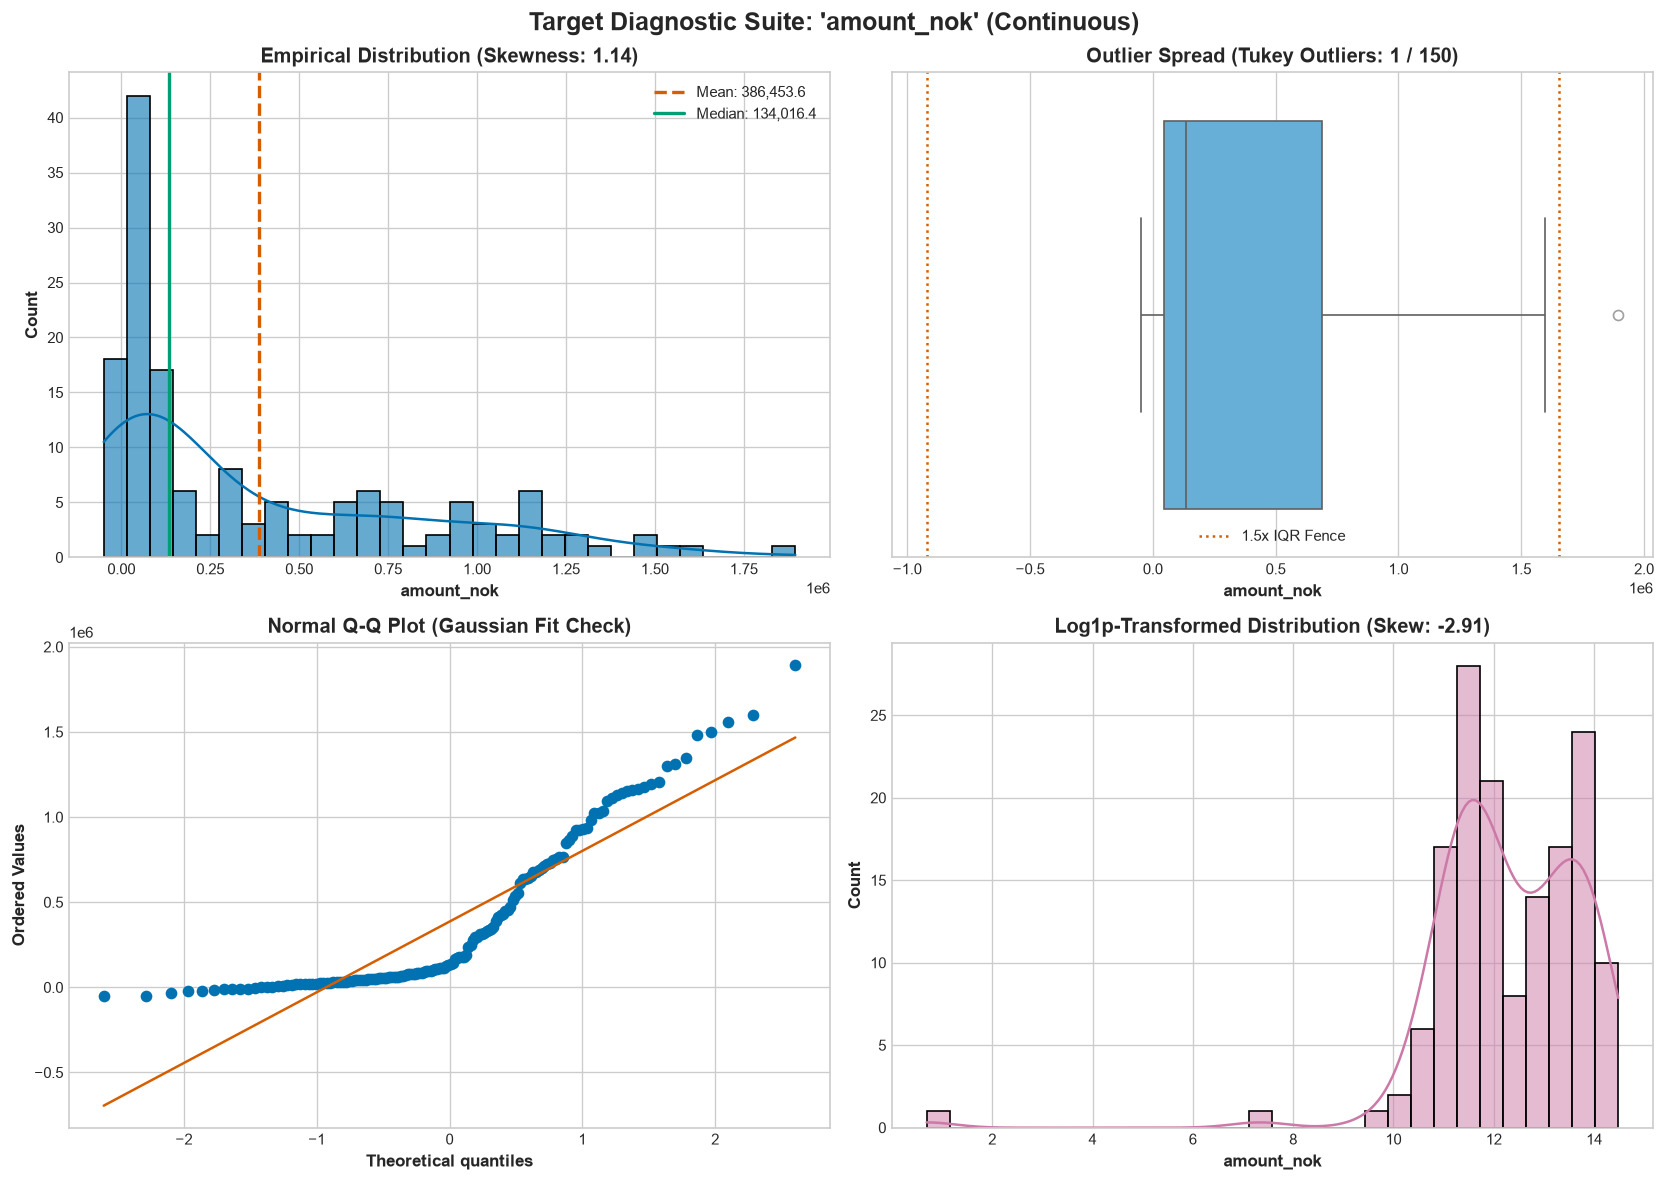

,Metric,Value
0,Count,150
1,Mean,"386,453.61"
2,Std Dev,"453,045.02"
3,Median,"134,016.42"
4,IQR (Q75 - Q25),"643,594.81"
5,Skewness,1.139
6,Kurtosis,0.276
7,Outlier Count,1 (0.7%)


In [44]:
# Cell 5: Comprehensive Target Analysis
def perform_target_analysis(df, target_col, target_type):
    """Generates diagnostic visualizations and statistics for the Target variable."""
    data = df[target_col].dropna()
    
    if target_type in ['numeric_continuous', 'numeric_discrete'] and data.nunique() > 10:
        # Continuous Target
        mean_val = data.mean()
        median_val = data.median()
        std_val = data.std()
        q25, q75 = data.quantile(0.25), data.quantile(0.75)
        iqr = q75 - q25
        lower_bound = q25 - 1.5 * iqr
        upper_bound = q75 + 1.5 * iqr
        outliers = data[(data < lower_bound) | (data > upper_bound)]
        skew_val = stats.skew(data)
        kurt_val = stats.kurtosis(data)
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f"Target Diagnostic Suite: '{target_col}' (Continuous)", fontsize=15, fontweight='bold', y=0.98)
        
        # 1. Distribution (KDE + Histogram)
        ax1 = axes[0, 0]
        sns.histplot(data, kde=True, ax=ax1, color='#0072B2', bins=30, alpha=0.6)
        ax1.axvline(mean_val, color='#D55E00', linestyle='--', linewidth=2, label=f'Mean: {mean_val:,.1f}')
        ax1.axvline(median_val, color='#009E73', linestyle='-', linewidth=2, label=f'Median: {median_val:,.1f}')
        ax1.set_title(f"Empirical Distribution (Skewness: {skew_val:.2f})")
        ax1.legend()
        
        # 2. Outlier Detection Boxplot
        ax2 = axes[0, 1]
        sns.boxplot(x=data, ax=ax2, color='#56B4E9', flierprops={'marker':'o', 'color':'#D55E00', 'alpha':0.6})
        ax2.axvline(lower_bound, color='#D55E00', linestyle=':', label='1.5x IQR Fence')
        ax2.axvline(upper_bound, color='#D55E00', linestyle=':')
        ax2.set_title(f"Outlier Spread (Tukey Outliers: {len(outliers)} / {len(data)})")
        ax2.legend()
        
        # 3. Probability / Q-Q Plot
        ax3 = axes[1, 0]
        stats.probplot(data, dist="norm", plot=ax3)
        ax3.get_lines()[0].set_color('#0072B2')
        ax3.get_lines()[1].set_color('#D55E00')
        ax3.set_title("Normal Q-Q Plot (Gaussian Fit Check)")
        
        # 4. Log Transformation Check
        ax4 = axes[1, 1]
        min_shift = abs(min(0, data.min())) + 1
        log_data = np.log1p(data + min_shift)
        sns.histplot(log_data, kde=True, ax=ax4, color='#CC79A7', bins=30)
        ax4.set_title(f"Log1p-Transformed Distribution (Skew: {stats.skew(log_data):.2f})")
        
        plt.tight_layout()
        plt.show()
        
        stats_summary = pd.DataFrame([{
            "Metric": "Count", "Value": f"{len(data):,}"
        }, {
            "Metric": "Mean", "Value": f"{mean_val:,.2f}"
        }, {
            "Metric": "Std Dev", "Value": f"{std_val:,.2f}"
        }, {
            "Metric": "Median", "Value": f"{median_val:,.2f}"
        }, {
            "Metric": "IQR (Q75 - Q25)", "Value": f"{iqr:,.2f}"
        }, {
            "Metric": "Skewness", "Value": f"{skew_val:.3f}"
        }, {
            "Metric": "Kurtosis", "Value": f"{kurt_val:.3f}"
        }, {
            "Metric": "Outlier Count", "Value": f"{len(outliers)} ({len(outliers)/len(data)*100:.1f}%)"
        }])
        return stats_summary
    else:
        # Categorical Target
        counts = data.value_counts()
        pcts = data.value_counts(normalize=True) * 100
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Target Diagnostic Suite: '{target_col}' (Categorical)", fontsize=15, fontweight='bold', y=1.02)
        
        sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax1, palette=PALETTE)
        for c in ax1.containers:
            ax1.bar_label(c, fmt='%d', padding=3, fontweight='bold')
        ax1.set_title("Class Frequency Distribution")
        ax1.set_ylabel("Count")
        ax1.tick_params(axis='x', rotation=30)
        
        ax2.pie(counts.values, labels=counts.index.astype(str), autopct='%1.1f%%',
                colors=PALETTE[:len(counts)], startangle=140,
                wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
        ax2.set_title("Class Proportions (Imbalance Ratio)")
        
        plt.tight_layout()
        plt.show()
        
        stats_summary = pd.DataFrame({
            "Class": counts.index,
            "Count": counts.values,
            "Percentage": pcts.values
        })
        return stats_summary

perform_target_analysis(df, target_col, target_type)


## 5. Traditional EDA — Univariate Features Analysis (`Features`)
Univariate inspection of all non-target feature columns:
- **Numerical Features**: Histograms with overlaid kernel density estimates and boxplot marginals.
- **Categorical Features**: Ranked Pareto bar charts with cumulative percentage thresholds.
- **Temporal Features**: Activity volume timeline.


Features Identified: 0 Numeric, 3 Categorical, 1 Datetime


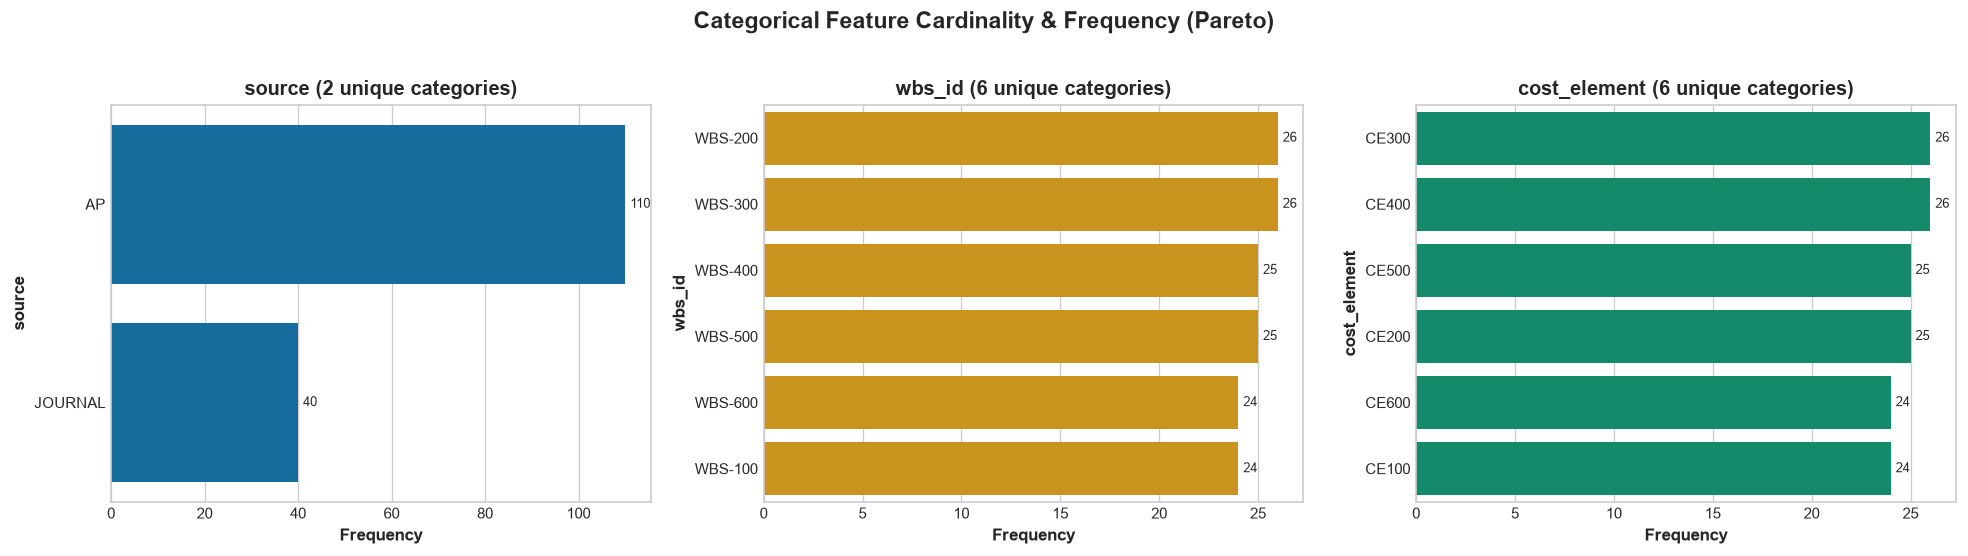

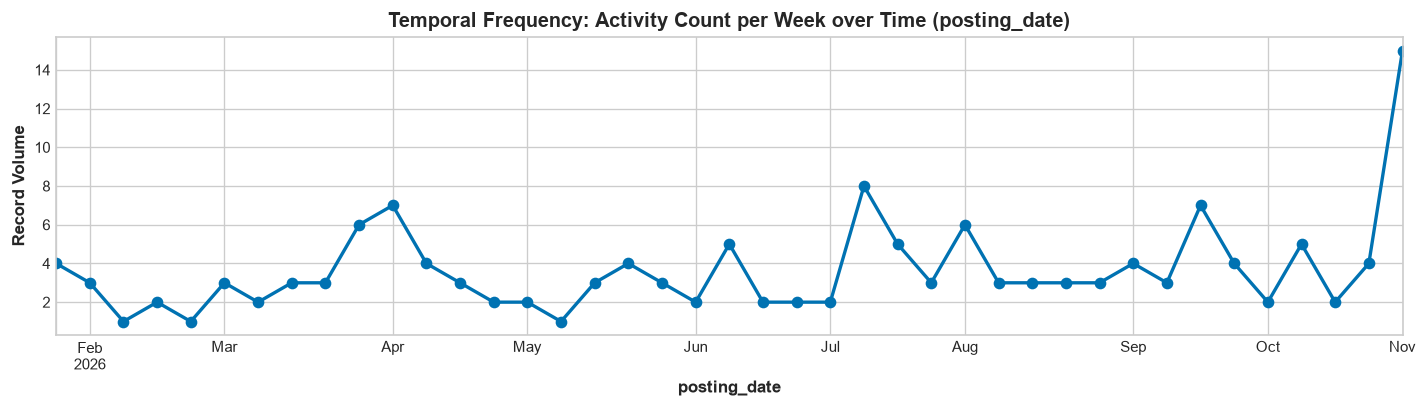

In [45]:
# Cell 6: Univariate Features Analysis
def analyze_univariate_features(df, type_map, target_col):
    """Generates clean distributions for non-target features."""
    feature_cols = [c for c in df.columns if c != target_col and type_map[c] != 'identifier']
    
    num_features = [c for c in feature_cols if type_map[c] in ['numeric_continuous', 'numeric_discrete']]
    cat_features = [c for c in feature_cols if type_map[c] == 'categorical']
    date_features = [c for c in feature_cols if type_map[c] == 'datetime']
    
    print(f"Features Identified: {len(num_features)} Numeric, {len(cat_features)} Categorical, {len(date_features)} Datetime")
    
    # Plot numerical features
    if num_features:
        ncols = min(3, len(num_features))
        nrows = math.ceil(len(num_features) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
        axes = np.array(axes).reshape(-1)
        fig.suptitle("Univariate Numerical Feature Distributions", fontsize=14, fontweight='bold', y=1.02)
        
        for idx, col in enumerate(num_features):
            ax = axes[idx]
            sns.histplot(df[col].dropna(), kde=True, ax=ax, color=PALETTE[idx % len(PALETTE)])
            ax.set_title(f"{col} (Skew: {stats.skew(df[col].dropna()):.2f})")
            ax.set_xlabel("")
            
        for idx in range(len(num_features), len(axes)):
            fig.delaxes(axes[idx])
        plt.tight_layout()
        plt.show()
        
    # Plot categorical features (Pareto frequency charts)
    if cat_features:
        ncols = min(3, len(cat_features))
        nrows = math.ceil(len(cat_features) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows))
        axes = np.array(axes).reshape(-1)
        fig.suptitle("Categorical Feature Cardinality & Frequency (Pareto)", fontsize=14, fontweight='bold', y=1.02)
        
        for idx, col in enumerate(cat_features):
            ax = axes[idx]
            top_cats = df[col].value_counts().head(10)
            sns.barplot(x=top_cats.values, y=top_cats.index.astype(str), ax=ax, color=PALETTE[idx % len(PALETTE)])
            for c in ax.containers:
                ax.bar_label(c, fmt='%d', padding=3, fontsize=8)
            ax.set_title(f"{col} ({df[col].nunique()} unique categories)")
            ax.set_xlabel("Frequency")
            
        for idx in range(len(cat_features), len(axes)):
            fig.delaxes(axes[idx])
        plt.tight_layout()
        plt.show()
        
    # Plot datetime trends
    if date_features:
        for col in date_features:
            fig, ax = plt.subplots(figsize=(12, 3.5))
            date_counts = df.set_index(col).resample('W').size()
            date_counts.plot(ax=ax, color='#0072B2', marker='o', linewidth=2)
            ax.set_title(f"Temporal Frequency: Activity Count per Week over Time ({col})", fontweight='bold')
            ax.set_ylabel("Record Volume")
            plt.tight_layout()
            plt.show()

analyze_univariate_features(df, type_map, target_col)


## 6. Traditional EDA — Feature-to-Feature Interactions (`Feature / Features`)
Multivariate relationships between independent features:
- **Numerical x Numerical**: Linear Pearson & Monotonic Spearman Correlation Heatmaps, Multicollinearity Detection (|r| > 0.70).
- **Categorical x Categorical**: Association matrix via Cramér's V statistic.


Note: Fewer than 2 numeric features available for feature-to-feature correlation.


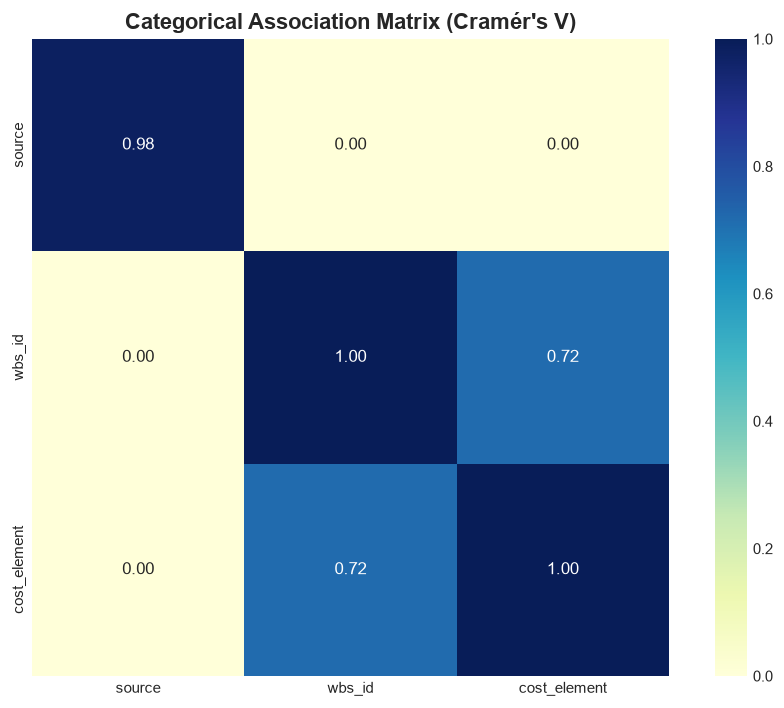

In [46]:
# Cell 7: Feature x Feature Interactions
def analyze_feature_interactions(df, type_map, target_col):
    """Calculates correlation structures and cross-associations between features."""
    feature_cols = [c for c in df.columns if c != target_col and type_map[c] != 'identifier']
    num_features = [c for c in feature_cols if type_map[c] in ['numeric_continuous', 'numeric_discrete']]
    cat_features = [c for c in feature_cols if type_map[c] == 'categorical']
    
    # 1. Numerical Correlations
    if len(num_features) >= 2:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
        fig.suptitle("Feature Correlation Architecture", fontsize=15, fontweight='bold', y=1.02)
        
        corr_pearson = df[num_features].corr(method='pearson')
        corr_spearman = df[num_features].corr(method='spearman')
        
        sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax1, square=True)
        ax1.set_title("Pearson Linear Correlation")
        
        sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax2, square=True)
        ax2.set_title("Spearman Rank Correlation")
        
        plt.tight_layout()
        plt.show()
        
        # High Multicollinearity Check
        collinear_pairs = []
        for i in range(len(num_features)):
            for j in range(i + 1, len(num_features)):
                f1, f2 = num_features[i], num_features[j]
                r_val = corr_pearson.loc[f1, f2]
                if abs(r_val) >= 0.70:
                    collinear_pairs.append({"Feature 1": f1, "Feature 2": f2, "Correlation": r_val})
                    
        if collinear_pairs:
            print("WARNING: High Multicollinearity Detected (|r| >= 0.70):")
            print(pd.DataFrame(collinear_pairs))
        else:
            print("No severe multicollinearity found between numeric features (|r| < 0.70).")
    else:
        print("Note: Fewer than 2 numeric features available for feature-to-feature correlation.")
        
    # 2. Categorical x Categorical Associations (Cramér's V)
    def cramers_v(x, y):
        confusion_matrix = pd.crosstab(x, y)
        chi2 = stats.chi2_contingency(confusion_matrix)[0]
        n = confusion_matrix.sum().sum()
        phi2 = chi2 / n
        r, k = confusion_matrix.shape
        phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
        rcorr = r - ((r-1)**2)/(n-1)
        kcorr = k - ((k-1)**2)/(n-1)
        if min((kcorr-1), (rcorr-1)) == 0:
            return 0.0
        return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))
        
    if len(cat_features) >= 2:
        cv_matrix = pd.DataFrame(index=cat_features, columns=cat_features, dtype=float)
        for c1 in cat_features:
            for c2 in cat_features:
                cv_matrix.loc[c1, c2] = cramers_v(df[c1], df[c2])
                
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(cv_matrix, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax, square=True)
        ax.set_title("Categorical Association Matrix (Cramér's V)", fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

analyze_feature_interactions(df, type_map, target_col)


## 7. Traditional EDA — Target-to-Feature Relationships (`Target / Features`)
Predictive bivariate analysis linking input features directly to the target:
- **Continuous Target**:
  - Regression scatter plots with 95% confidence intervals and linear trend.
  - Correlation Ranking: Quantifying the predictive strength of each numerical feature.
  - Categorical Impact: Grouped boxplots & ANOVA F-test statistical significance.
- **Categorical Target**:
  - Grouped distributions (boxplots / KDE) per target class.
  - 100% Normalized Stacked Bar Charts (class composition across categories).



ANOVA Test for Categorical Predictors of Target:
Categorical Feature  F-Statistic      p-value
             source    44.007014 5.762686e-10
       cost_element    11.447365 2.581847e-09
             wbs_id    10.408869 1.536844e-08


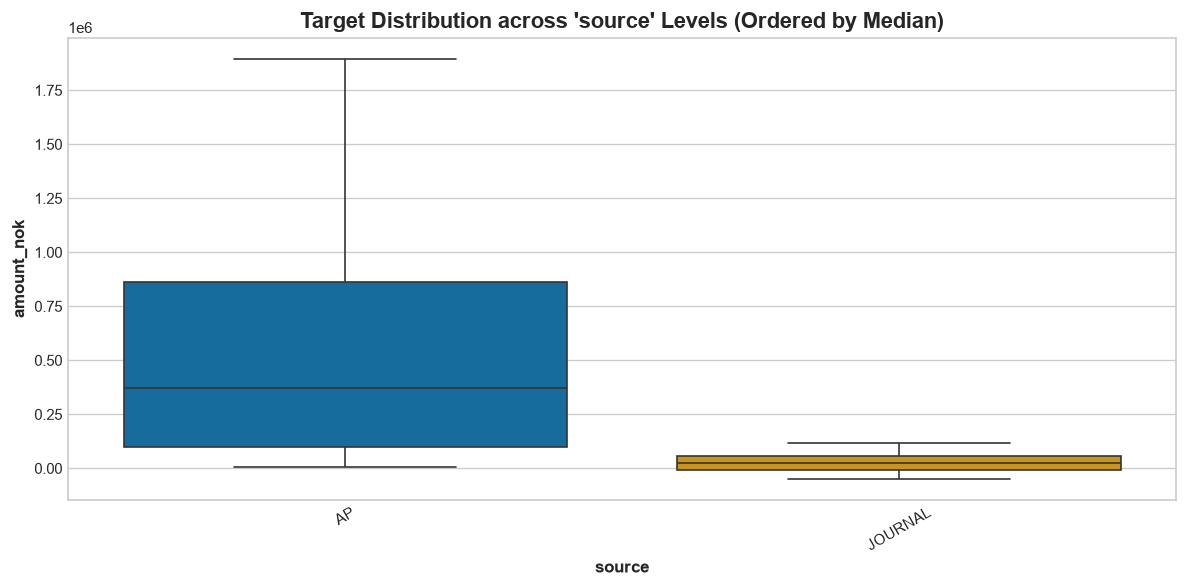

In [47]:
# Cell 8: Target x Features Relationships
def analyze_target_relationships(df, type_map, target_col, target_type):
    """Analyzes how individual features drive or explain the target variable."""
    feature_cols = [c for c in df.columns if c != target_col and type_map[c] != 'identifier']
    num_features = [c for c in feature_cols if type_map[c] in ['numeric_continuous', 'numeric_discrete']]
    cat_features = [c for c in feature_cols if type_map[c] == 'categorical']
    
    if target_type in ['numeric_continuous', 'numeric_discrete'] and df[target_col].nunique() > 10:
        # 1. Numerical Features vs Target
        if num_features:
            corrs = {feat: df[feat].corr(df[target_col]) for feat in num_features}
            corr_series = pd.Series(corrs).sort_values()
            
            fig, ax = plt.subplots(figsize=(8, max(3, len(num_features) * 0.6)))
            colors = ['#D55E00' if v < 0 else '#0072B2' for v in corr_series.values]
            corr_series.plot(kind='barh', ax=ax, color=colors)
            ax.axvline(0, color='gray', linestyle='--')
            ax.set_title(f"Feature Correlation with Target: '{target_col}'", fontsize=13, fontweight='bold')
            ax.set_xlabel("Pearson Correlation Coefficient")
            plt.tight_layout()
            plt.show()
            
            # Scatter / Regplots for top features
            top_feats = list(corr_series.abs().sort_values(ascending=False).index[:4])
            ncols = min(2, len(top_feats))
            nrows = math.ceil(len(top_feats) / ncols)
            fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows))
            axes = np.array(axes).reshape(-1)
            fig.suptitle(f"Bivariate Scatter & Trendlines vs Target ({target_col})", fontsize=14, fontweight='bold', y=1.02)
            
            for idx, feat in enumerate(top_feats):
                ax = axes[idx]
                sns.regplot(data=df, x=feat, y=target_col, ax=ax, color=PALETTE[idx % len(PALETTE)],
                            scatter_kws={'alpha': 0.6}, line_kws={'color': '#D55E00', 'linewidth': 2})
                r = df[feat].corr(df[target_col])
                ax.set_title(f"{feat} vs {target_col} (r = {r:.2f})")
                
            for idx in range(len(top_feats), len(axes)):
                fig.delaxes(axes[idx])
            plt.tight_layout()
            plt.show()
            
        # 2. Categorical Features vs Target
        if cat_features:
            anova_results = []
            for col in cat_features:
                groups = [group.dropna() for _, group in df.groupby(col)[target_col]]
                if len(groups) >= 2:
                    try:
                        f_stat, p_val = stats.f_oneway(*groups)
                        anova_results.append({"Categorical Feature": col, "F-Statistic": f_stat, "p-value": p_val})
                    except:
                        pass
            if anova_results:
                anova_df = pd.DataFrame(anova_results).sort_values("F-Statistic", ascending=False)
                print("\nANOVA Test for Categorical Predictors of Target:")
                print(anova_df.to_string(index=False))
                
            # Plot Target Boxplot by top categorical features
            top_cat = cat_features[0]
            fig, ax = plt.subplots(figsize=(10, 5))
            order = df.groupby(top_cat)[target_col].median().sort_values(ascending=False).index
            sns.boxplot(data=df, x=top_cat, y=target_col, order=order, ax=ax, palette=PALETTE)
            ax.set_title(f"Target Distribution across '{top_cat}' Levels (Ordered by Median)", fontsize=13, fontweight='bold')
            ax.tick_params(axis='x', rotation=30)
            plt.tight_layout()
            plt.show()
    else:
        # Categorical Target
        if num_features:
            ncols = min(2, len(num_features))
            nrows = math.ceil(len(num_features) / ncols)
            fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows))
            axes = np.array(axes).reshape(-1)
            fig.suptitle(f"Numerical Features Grouped by Target Class ({target_col})", fontsize=14, fontweight='bold', y=1.02)
            
            for idx, feat in enumerate(num_features[:4]):
                ax = axes[idx]
                sns.boxplot(data=df, x=target_col, y=feat, ax=ax, palette=PALETTE)
                ax.set_title(f"{feat} by {target_col}")
                
            for idx in range(min(4, len(num_features)), len(axes)):
                fig.delaxes(axes[idx])
            plt.tight_layout()
            plt.show()
            
        if cat_features:
            # 100% normalized stacked bar chart
            top_cat = cat_features[0]
            ct = pd.crosstab(df[top_cat], df[target_col], normalize='index') * 100
            ax = ct.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab10')
            ax.set_title(f"Class Composition (%) across '{top_cat}' Levels", fontsize=13, fontweight='bold')
            ax.set_ylabel("Percentage (%)")
            ax.legend(title=target_col, bbox_to_anchor=(1.02, 1), loc='upper left')
            plt.tight_layout()
            plt.show()

analyze_target_relationships(df, type_map, target_col, target_type)


## 8. Visual Vocabulary Suite (The 9 FT Data Storytelling Angles)
Drawing from the **Financial Times Visual Vocabulary**, this module expands beyond routine EDA charts into specialized storytelling visualization types:
1. **Deviation**: Diverging Bar Chart (Variance vs. Baseline/Mean, Surplus vs. Deficit).
2. **Correlation**: Residual Scatter & 2D Trendline.
3. **Change over Time**: Cumulative Trajectory & Moving Average Trend.
4. **Ranking**: Ordered Horizontal Lollipop Chart of entity magnitudes.
5. **Distribution**: Multi-category Violin & Kernel Density Spread.
6. **Part-to-Whole**: Pareto 80/20 Analysis (Concentration Curve).
7. **Magnitude**: Small Multiples (Faceted comparisons).
8. **Spatial / Groups**: Categorical Group Comparison.
9. **Flow / Relational**: Dependency or Event Sequence Overview.


Generating Visual Vocabulary multi-perspective gallery...


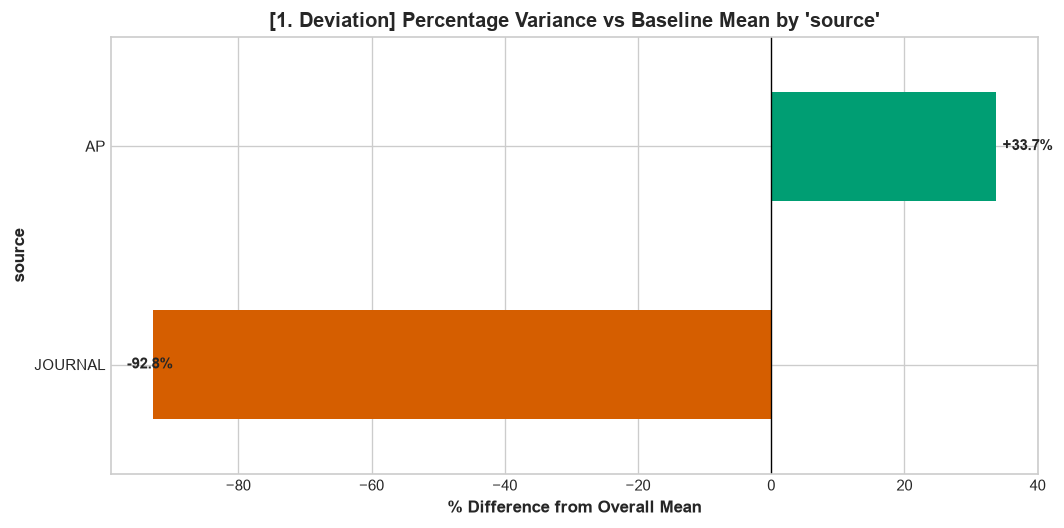

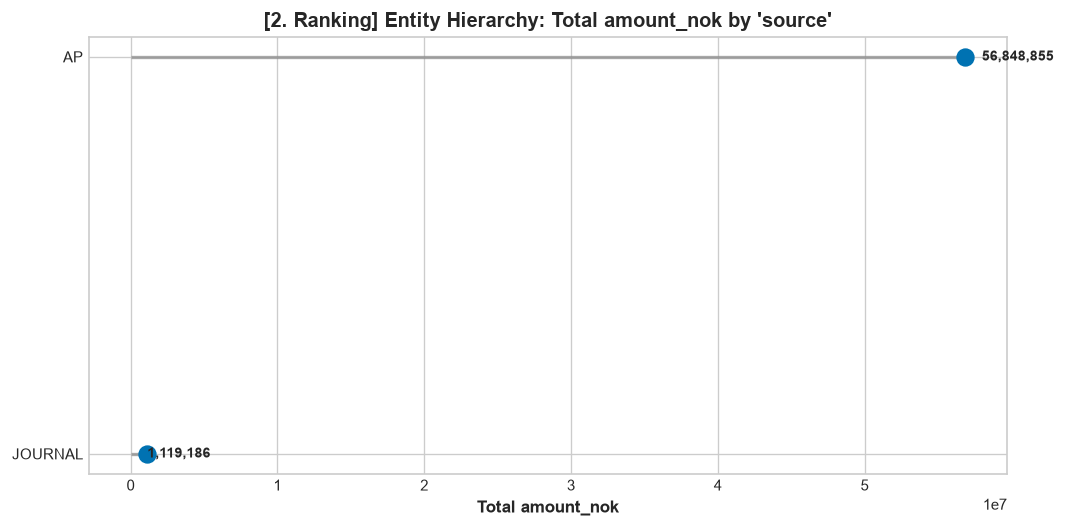

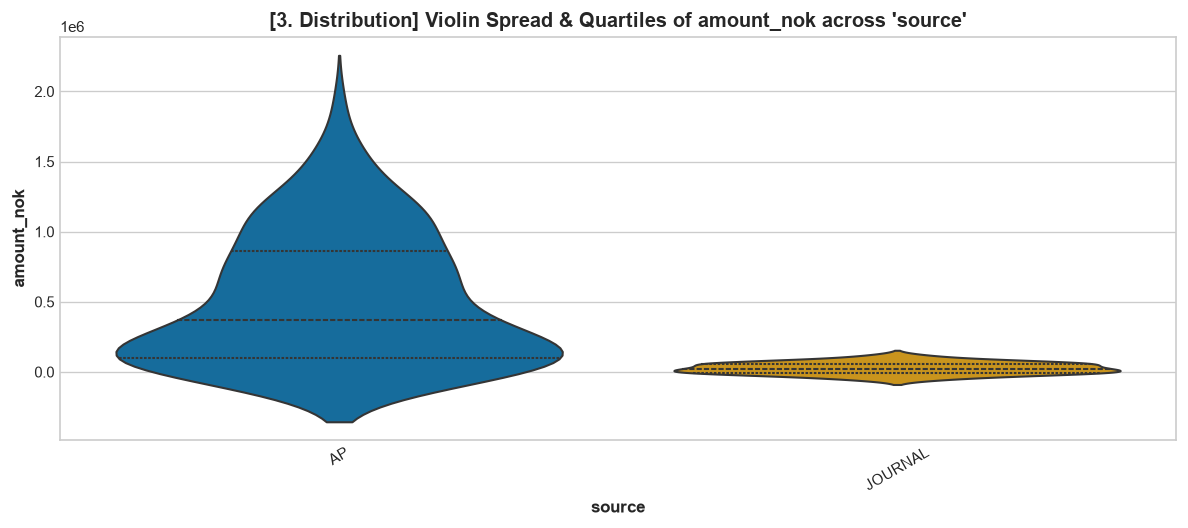

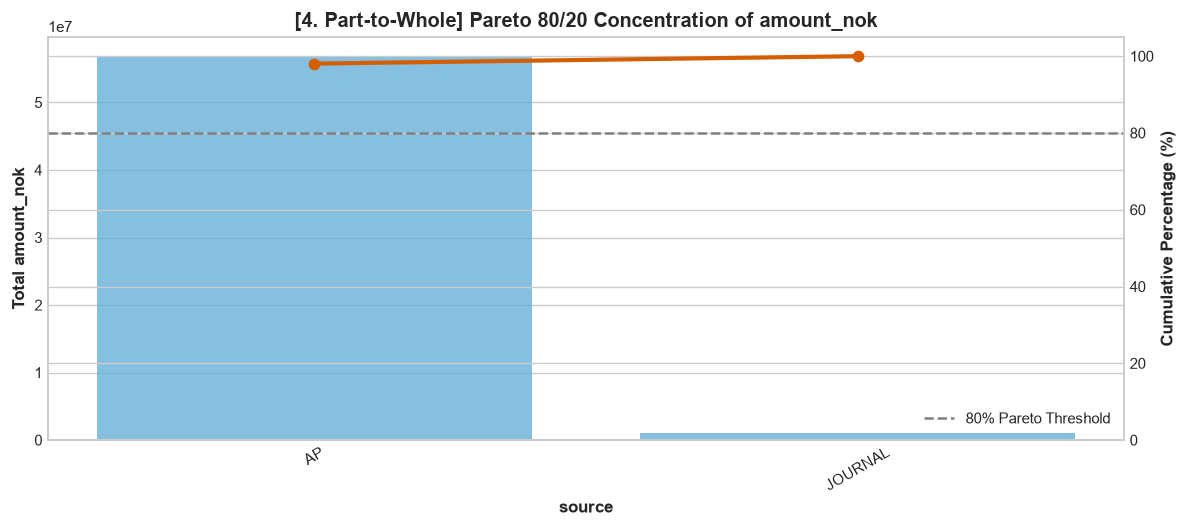

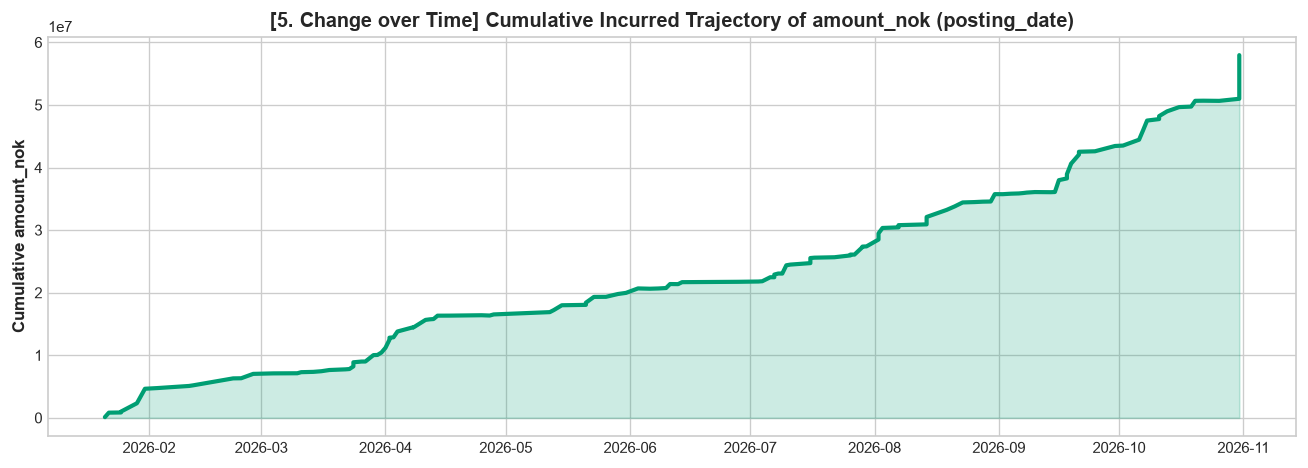

In [48]:
# Cell 9: Visual Vocabulary Multi-Angle Suite
def generate_visual_vocabulary_suite(df, type_map, target_col):
    """Implements diverse chart types from the 9 Visual Vocabulary categories."""
    print("Generating Visual Vocabulary multi-perspective gallery...")
    
    # --- 1. DEVIATION: Diverging Bar Chart vs Mean ---
    if type_map[target_col] == 'numeric_continuous':
        cat_col = [c for c, t in type_map.items() if t == 'categorical'][0]
        group_means = df.groupby(cat_col)[target_col].mean()
        overall_mean = df[target_col].mean()
        variance = (group_means - overall_mean) / overall_mean * 100
        variance = variance.sort_values()
        
        fig, ax = plt.subplots(figsize=(9, 4.5))
        colors = ['#D55E00' if x < 0 else '#009E73' for x in variance.values]
        variance.plot(kind='barh', ax=ax, color=colors)
        ax.axvline(0, color='black', linewidth=0.8)
        for i, v in enumerate(variance):
            ax.text(v + (1 if v >= 0 else -4), i, f"{v:+.1f}%", va='center', fontsize=9, fontweight='bold')
        ax.set_title(f"[1. Deviation] Percentage Variance vs Baseline Mean by '{cat_col}'", fontweight='bold')
        ax.set_xlabel("% Difference from Overall Mean")
        plt.tight_layout()
        plt.show()
        
    # --- 2. RANKING: Horizontal Lollipop Chart ---
    cat_col = [c for c, t in type_map.items() if t == 'categorical'][0]
    agg_vals = df.groupby(cat_col)[target_col].sum().sort_values(ascending=True)
    
    fig, ax = plt.subplots(figsize=(9, 4.5))
    y_range = range(len(agg_vals))
    ax.hlines(y=y_range, xmin=0, xmax=agg_vals.values, color='#888888', alpha=0.7, linewidth=2)
    ax.scatter(agg_vals.values, y_range, color='#0072B2', s=100, zorder=3)
    ax.set_yticks(y_range)
    ax.set_yticklabels(agg_vals.index)
    for i, val in enumerate(agg_vals.values):
        ax.text(val * 1.02, i, f"{val:,.0f}", va='center', fontsize=8.5, fontweight='bold')
    ax.set_title(f"[2. Ranking] Entity Hierarchy: Total {target_col} by '{cat_col}'", fontweight='bold')
    ax.set_xlabel(f"Total {target_col}")
    plt.tight_layout()
    plt.show()
    
    # --- 3. DISTRIBUTION: Multi-Category Violin Plot ---
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.violinplot(data=df, x=cat_col, y=target_col, ax=ax, palette=PALETTE, inner='quartile', scale='width')
    ax.set_title(f"[3. Distribution] Violin Spread & Quartiles of {target_col} across '{cat_col}'", fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()
    
    # --- 4. PART-TO-WHOLE: Pareto Cumulative Distribution ---
    counts = df.groupby(cat_col)[target_col].sum().sort_values(ascending=False)
    cum_pct = counts.cumsum() / counts.sum() * 100
    
    fig, ax1 = plt.subplots(figsize=(10, 4.5))
    ax2 = ax1.twinx()
    
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax1, color='#56B4E9', alpha=0.8)
    ax2.plot(range(len(counts)), cum_pct.values, color='#D55E00', marker='o', linewidth=2.5)
    ax2.axhline(80, color='gray', linestyle='--', label='80% Pareto Threshold')
    
    ax1.set_title(f"[4. Part-to-Whole] Pareto 80/20 Concentration of {target_col}", fontweight='bold')
    ax1.set_ylabel(f"Total {target_col}")
    ax2.set_ylabel("Cumulative Percentage (%)")
    ax2.set_ylim(0, 105)
    ax1.tick_params(axis='x', rotation=30)
    ax2.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
    
    # --- 5. CHANGE OVER TIME: Cumulative Trajectory ---
    date_cols = [c for c, t in type_map.items() if t == 'datetime']
    if date_cols:
        d_col = date_cols[0]
        ts_df = df.dropna(subset=[d_col]).sort_values(d_col)
        ts_df['Cumulative_Target'] = ts_df[target_col].cumsum()
        
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(ts_df[d_col], ts_df['Cumulative_Target'], color='#009E73', linewidth=2.5)
        ax.fill_between(ts_df[d_col], ts_df['Cumulative_Target'], alpha=0.2, color='#009E73')
        ax.set_title(f"[5. Change over Time] Cumulative Incurred Trajectory of {target_col} ({d_col})", fontweight='bold')
        ax.set_ylabel(f"Cumulative {target_col}")
        plt.tight_layout()
        plt.show()

generate_visual_vocabulary_suite(df, type_map, target_col)


## 9. Automated Executive Insight Synthesis
Generates an executive-ready text summary compiling all primary statistical takeaways, high-risk anomalies, dominant drivers, and data quality highlights.


In [49]:
# Cell 10: Executive Insights Generation
def generate_executive_insights(df, type_map, target_col, target_type):
    """Synthesizes findings into structured executive takeaways."""
    data = df[target_col].dropna()
    print("=" * 70)
    print("EXECUTIVE DATA INSIGHT SUMMARY")
    print("=" * 70)
    
    print(f"\n1. Dataset Dimensions: {len(df):,} total records across {len(df.columns)} columns.")
    
    # Target stats
    if target_type in ['numeric_continuous', 'numeric_discrete'] and data.nunique() > 10:
        mean_v = data.mean()
        med_v = data.median()
        skew_v = stats.skew(data)
        q25, q75 = data.quantile(0.25), data.quantile(0.75)
        outliers = data[(data < q25 - 1.5*(q75-q25)) | (data > q75 + 1.5*(q75-q25))]
        
        print(f"\n2. Target Metric ('{target_col}'):")
        print(f"   - Average: {mean_v:,.2f} | Median: {med_v:,.2f}")
        print(f"   - Distribution Shape: {'Positively Skewed (Heavy Right Tail)' if skew_v > 0.5 else 'Negatively Skewed' if skew_v < -0.5 else 'Approximately Symmetric'} (Skew = {skew_v:.2f})")
        print(f"   - Outlier Density: {len(outliers)} records ({len(outliers)/len(data)*100:.1f}%) exceed 1.5x IQR boundaries.")
    else:
        top_class = data.value_counts().index[0]
        top_share = data.value_counts(normalize=True).iloc[0] * 100
        print(f"\n2. Target Class Balance ('{target_col}'):")
        print(f"   - Dominant Class: '{top_class}' representing {top_share:.1f}% of total population.")
        print(f"   - Total Distinct Classes: {data.nunique()}")
        
    # Top drivers
    cat_features = [c for c, t in type_map.items() if t == 'categorical' and c != target_col]
    if cat_features and target_type in ['numeric_continuous', 'numeric_discrete'] and data.nunique() > 10:
        top_cat = cat_features[0]
        group_totals = df.groupby(top_cat)[target_col].sum().sort_values(ascending=False)
        top_entity = group_totals.index[0]
        top_entity_pct = (group_totals.iloc[0] / group_totals.sum()) * 100
        print(f"\n3. Primary Categorical Driver ('{top_cat}'):")
        print(f"   - '{top_entity}' is the single largest contributor, driving {top_entity_pct:.1f}% of total {target_col}.")
        
    # Data Quality Flags
    missing_cols = {col: df[col].isna().sum() for col in df.columns if df[col].isna().sum() > 0}
    print(f"\n4. Data Quality & Integrity Checks:")
    if missing_cols:
        print(f"   - Missing Values Detected in: {missing_cols}")
    else:
        print("   - High Integrity: Zero null/missing values found across active fields.")
    print("=" * 70)

generate_executive_insights(df, type_map, target_col, target_type)


EXECUTIVE DATA INSIGHT SUMMARY

1. Dataset Dimensions: 150 total records across 7 columns.

2. Target Metric ('amount_nok'):
   - Average: 386,453.61 | Median: 134,016.42
   - Distribution Shape: Positively Skewed (Heavy Right Tail) (Skew = 1.14)
   - Outlier Density: 1 records (0.7%) exceed 1.5x IQR boundaries.

3. Primary Categorical Driver ('source'):
   - 'AP' is the single largest contributor, driving 98.1% of total amount_nok.

4. Data Quality & Integrity Checks:
   - High Integrity: Zero null/missing values found across active fields.
